In [1]:
# base modules
from pathlib import Path

# for manipulating data
import numpy as np
import pandas as pd
import sklearn

# forMachine Learning
from sklearn.ensemble import RandomForestRegressor

In [2]:
# for package auto reload
%load_ext autoreload
%autoreload 2

# for better rendering of plots in jupyter notebook
%matplotlib inline

In [3]:
from eclyon.transforms import (
    add_date_columns, 
    change_columns_from_str_to_categorical, 
    process_df,
)

DATA PREPROCESSING

In [4]:
df_raw = pd.read_csv('energy_weather_raw_data.csv', 
                     low_memory = False, 
                     parse_dates = ["date"]) #convert date column into a date format

In [5]:

df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 605260 entries, 0 to 605259
Data columns (total 19 columns):
 #   Column          Non-Null Count   Dtype         
---  ------          --------------   -----         
 0   date            605260 non-null  datetime64[ns]
 1   active_power    605260 non-null  float64       
 2   current         605260 non-null  float64       
 3   voltage         605260 non-null  float64       
 4   reactive_power  605260 non-null  float64       
 5   apparent_power  605260 non-null  float64       
 6   power_factor    605260 non-null  float64       
 7   main            605260 non-null  object        
 8   description     605260 non-null  object        
 9   temp            605260 non-null  float64       
 10  feels_like      605260 non-null  float64       
 11  temp_min        605260 non-null  float64       
 12  temp_max        605260 non-null  float64       
 13  pressure        605260 non-null  int64         
 14  humidity        605260 non-null  int

In [6]:
df_raw = df_raw.convert_dtypes()

In [7]:
df_raw

,date,active_power,current,voltage,reactive_power,apparent_power,power_factor,main,description,temp,feels_like,temp_min,temp_max,pressure,humidity,speed,deg,temp_t+1,feels_like_t+1
0,2022-11-05 14:05:00,265.1,2.53,122.2,159.09,309.17,0.8575,Clear,clear sky,24.19,23.68,23.44,27.5,1013,39,0.0,0,29.63,27.97
1,2022-11-05 14:06:00,265.1,2.53,122.2,159.09,309.17,0.8575,Clear,clear sky,24.19,23.68,23.44,27.5,1013,39,0.0,0,29.63,27.97
2,2022-11-05 14:07:00,265.1,2.53,122.2,159.09,309.17,0.8575,Clear,clear sky,24.19,23.68,23.44,27.5,1013,39,0.0,0,29.63,27.97
3,2022-11-05 14:08:00,640.0,5.45,120.7,152.08,657.82,0.9729,Clear,clear sky,24.19,23.68,23.44,27.5,1013,39,0.0,0,29.63,27.97
4,2022-11-05 14:09:00,257.6,2.47,122.4,158.26,302.33,0.852,Clear,clear sky,24.19,23.68,23.44,27.5,1013,39,0.0,0,29.63,27.97
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
605255,2024-01-05 23:55:00,316.3,2.53,129.1,81.46,326.62,0.9684,Clouds,few clouds,12.32,10.65,8.07,13.96,1012,40,2.05,160,13.99,12.75
605256,2024-01-05 23:56:00,1526.3,13.58,124.8,736.67,1694.78,0.9006,Clouds,few clouds,12.76,11.11,8.07,13.96,1012,39,2.05,160,13.99,12.75
605257,2024-01-05 23:57:00,1528.7,13.56,124.9,729.04,1693.64,0.9026,Clouds,few clouds,12.32,10.65,8.07,13.96,1012,40,2.05,160,13.96,12.72
605258,2024-01-05 23:58:00,283.4,2.26,129.6,73.99,292.9,0.9676,Clouds,few clouds,12.76,11.11,8.07,13.96,1012,39,2.05,160,13.99,12.75


In [8]:
len(df_raw.columns)

19

In [9]:
df_raw.shape

(605260, 19)

In [10]:
def display_all(df):
    with pd.option_context("display.max_rows", 1000, "display.max_columns", 1000): 
        display(df)

In [11]:
display_all(df_raw.head().T)

,0,1,2,3,4
date,2022-11-05 14:05:00,2022-11-05 14:06:00,2022-11-05 14:07:00,2022-11-05 14:08:00,2022-11-05 14:09:00
active_power,265.1,265.1,265.1,640.0,257.6
current,2.53,2.53,2.53,5.45,2.47
voltage,122.2,122.2,122.2,120.7,122.4
reactive_power,159.09,159.09,159.09,152.08,158.26
apparent_power,309.17,309.17,309.17,657.82,302.33
power_factor,0.8575,0.8575,0.8575,0.9729,0.852
main,Clear,Clear,Clear,Clear,Clear
description,clear sky,clear sky,clear sky,clear sky,clear sky
temp,24.19,24.19,24.19,24.19,24.19


In [12]:
display_all(df_raw.describe(include = 'all').T)

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
date,605260,NaN,NaN,NaN,2023-06-06 14:26:13.462776320,2022-11-05 14:05:00,2023-02-19 23:46:45,2023-06-05 12:05:30,2023-09-22 13:23:15,2024-01-05 23:59:00,NaN
active_power,605260.0,<NA>,<NA>,<NA>,286.019377,24.4,159.8,250.3,365.4,2900.0,189.545683
current,605260.0,<NA>,<NA>,<NA>,2.587303,0.3,1.61,2.29,3.22,24.41,1.591395
voltage,605260.0,<NA>,<NA>,<NA>,125.4173,107.6,122.6,124.4,129.5,135.5,4.390612
reactive_power,605260.0,<NA>,<NA>,<NA>,132.538007,4.73,74.07,128.5,177.6525,1293.58,71.030254
apparent_power,605260.0,<NA>,<NA>,<NA>,321.839271,37.14,203.58,286.44,401.47,2931.64,191.743962
power_factor,605260.0,<NA>,<NA>,<NA>,0.854202,0.2018,0.7546,0.8917,0.95,1.0,0.114629
main,605260,8,Clouds,293283,NaN,NaN,NaN,NaN,NaN,NaN,NaN
description,605260,16,clear sky,280521,NaN,NaN,NaN,NaN,NaN,NaN,NaN
temp,605260.0,<NA>,<NA>,<NA>,19.525256,-5.56,14.81,19.49,24.25,39.37,6.607351


We can see that there is no missing value

In [13]:
df_raw.active_power #we want to predict active power

0          265.1
1          265.1
2          265.1
3          640.0
4          257.6
           ...  
605255     316.3
605256    1526.3
605257    1528.7
605258     283.4
605259     283.4
Name: active_power, Length: 605260, dtype: Float64

In [14]:
activepower=df_raw.active_power.tolist()

In [15]:
df_raw.active_power = np.log(df_raw.active_power)

In [16]:
df_raw.active_power

0         5.580107
1         5.580107
2         5.580107
3         6.461468
4         5.551408
            ...   
605255    5.756691
605256    7.330602
605257    7.332173
605258    5.646859
605259    5.646859
Name: active_power, Length: 605260, dtype: Float64

convert date times

In [17]:
df_raw.date

0        2022-11-05 14:05:00
1        2022-11-05 14:06:00
2        2022-11-05 14:07:00
3        2022-11-05 14:08:00
4        2022-11-05 14:09:00
                 ...        
605255   2024-01-05 23:55:00
605256   2024-01-05 23:56:00
605257   2024-01-05 23:57:00
605258   2024-01-05 23:58:00
605259   2024-01-05 23:59:00
Name: date, Length: 605260, dtype: datetime64[ns]

In [18]:
# date-time object was created within the df with parse_dates=["saledate"]
df_raw.date.dt

In [19]:
# In order to separate our data per day and not per minute
df_raw['date_only'] = df_raw.date.dt.date

In [20]:
# In order to keep a dataset large enough and to make a distinction between the energy consumption at different time periods 
df_raw['time_block'] = df_raw.date.dt.hour // 6

In [21]:
df_raw['time_block'].value_counts()

time_block
3    151613
0    151315
2    151199
1    151133
Name: count, dtype: int64

In [22]:
# It automatically select all numeric columns to calculate their average
numeric_cols = df_raw.select_dtypes(include=[np.number]).columns.tolist()
if 'time_block' in numeric_cols:
    numeric_cols.remove('time_block')

In [23]:
# We create a dictionary with aggregation rules:
# "mean" for all numbers, and "first" for your two text columns
agg_rules = {col: 'mean' for col in numeric_cols}
agg_rules['main'] = 'first'
agg_rules['description'] = 'first'

In [24]:
# We group our data by both the Day and the Time Block
# df_block = df_raw.groupby(['date_only', 'time_block'])[numeric_cols].mean().reset_index()
df_block = df_raw.groupby(['date_only', 'time_block']).agg(agg_rules).reset_index()

In [25]:
df_block['date'] = pd.to_datetime(df_block['date_only'].astype(str)) + pd.to_timedelta(df_block['time_block'] * 6, unit='h')

In [26]:
df_raw = df_block.drop(columns=['date_only', 'time_block'])

In [27]:
# add_datepart adds new columns to the dataframe
df_transformed = add_date_columns(df_raw, fields = ['date'])

In [28]:
# comparaison of dataframe shape before & after applying add_datepart
print(df_raw.shape)
print(df_transformed.shape)

(1701, 19)
(1701, 30)


In [29]:
df_transformed.columns

Index(['active_power', 'current', 'voltage', 'reactive_power',
       'apparent_power', 'power_factor', 'temp', 'feels_like', 'temp_min',
       'temp_max', 'pressure', 'humidity', 'speed', 'deg', 'temp_t+1',
       'feels_like_t+1', 'main', 'description', 'Year', 'Month', 'Day',
       'Dayofweek', 'Dayofyear', 'Is_month_start', 'Is_month_end',
       'Is_quarter_start', 'Is_quarter_end', 'Is_year_start', 'Is_year_end',
       'Elapsed'],
      dtype='object')

Convert strings into numerotated categories

In [30]:
df_transformed = change_columns_from_str_to_categorical(df_transformed)

In [31]:
df_transformed.main

0        Clear
1        Clear
2        Clear
3        Clear
4        Clear
         ...  
1696     Clear
1697     Clear
1698    Clouds
1699     Clear
1700     Clear
Name: main, Length: 1701, dtype: category
Categories (8, string): [Clear < Clouds < Drizzle < Fog < Haze < Mist < Rain < Thunderstorm]

In [32]:
df_transformed.main.cat.categories.tolist()

['Clear', 'Clouds', 'Drizzle', 'Fog', 'Haze', 'Mist', 'Rain', 'Thunderstorm']

In [33]:
df_transformed.main.dtype

CategoricalDtype(categories=['Clear', 'Clouds', 'Drizzle', 'Fog', 'Haze', 'Mist', 'Rain',
                  'Thunderstorm'],
, ordered=True, categories_dtype=string)

In [34]:
df_transformed.main

0        Clear
1        Clear
2        Clear
3        Clear
4        Clear
         ...  
1696     Clear
1697     Clear
1698    Clouds
1699     Clear
1700     Clear
Name: main, Length: 1701, dtype: category
Categories (8, string): [Clear < Clouds < Drizzle < Fog < Haze < Mist < Rain < Thunderstorm]

In [35]:
df_transformed.main.cat.categories

Index(['Clear', 'Clouds', 'Drizzle', 'Fog', 'Haze', 'Mist', 'Rain',
       'Thunderstorm'],
      dtype='string')

In [36]:
df_transformed.main.cat.codes

0       0
1       0
2       0
3       0
4       0
       ..
1696    0
1697    0
1698    1
1699    0
1700    0
Length: 1701, dtype: int8

In [37]:
# This step overwrites the raw categories with integers
df_transformed.main = df_transformed.main.cat.codes

In [38]:
df_transformed.main

0       0
1       0
2       0
3       0
4       0
       ..
1696    0
1697    0
1698    1
1699    0
1700    0
Name: main, Length: 1701, dtype: int8

In [39]:
df_transformed.description

0        clear sky
1        clear sky
2        clear sky
3        clear sky
4        clear sky
           ...    
1696     clear sky
1697     clear sky
1698    few clouds
1699     clear sky
1700     clear sky
Name: description, Length: 1701, dtype: category
Categories (12, string): [broken clouds < clear sky < few clouds < fog ... moderate rain < overcast clouds < scattered clouds < thunderstorm]

Inspect missing values

In [40]:
display_all(df_transformed.isnull().sum().T) 

active_power        0
current             0
voltage             0
reactive_power      0
apparent_power      0
power_factor        0
temp                0
feels_like          0
temp_min            0
temp_max            0
pressure            0
humidity            0
speed               0
deg                 0
temp_t+1            0
feels_like_t+1      0
main                0
description         0
Year                0
Month               0
Day                 0
Dayofweek           0
Dayofyear           0
Is_month_start      0
Is_month_end        0
Is_quarter_start    0
Is_quarter_end      0
Is_year_start       0
Is_year_end         0
Elapsed             0
dtype: int64

In [41]:
df_processed, y, nas = process_df(df_transformed, y_field = 'active_power')

In [42]:
df_processed.columns

Index(['current', 'voltage', 'reactive_power', 'apparent_power',
       'power_factor', 'temp', 'feels_like', 'temp_min', 'temp_max',
       'pressure', 'humidity', 'speed', 'deg', 'temp_t+1', 'feels_like_t+1',
       'main', 'description', 'Year', 'Month', 'Day', 'Dayofweek', 'Dayofyear',
       'Is_month_start', 'Is_month_end', 'Is_quarter_start', 'Is_quarter_end',
       'Is_year_start', 'Is_year_end', 'Elapsed'],
      dtype='object')

In [43]:
df_processed.head()

,current,voltage,reactive_power,apparent_power,power_factor,temp,feels_like,temp_min,temp_max,pressure,...,Day,Dayofweek,Dayofyear,Is_month_start,Is_month_end,Is_quarter_start,Is_quarter_end,Is_year_start,Is_year_end,Elapsed
0,2.492511,122.410213,146.04383,303.861532,0.835184,24.047872,23.477277,23.724426,26.906043,1011.131915,...,5,5,309,False,False,False,False,False,False,1667649600
1,2.670472,124.017778,130.834111,329.970472,0.884407,18.233889,17.33875,17.784611,18.413389,1010.297222,...,5,5,309,False,False,False,False,False,False,1667671200
2,2.142145,125.583844,118.829387,268.466323,0.849922,16.133148,14.731978,16.133148,16.160167,1010.571031,...,6,6,310,False,False,False,False,False,False,1667692800
3,2.673156,124.591061,140.470363,329.763268,0.826241,19.375866,18.247542,17.480726,19.951397,1014.26257,...,6,6,310,False,False,False,False,False,False,1667714400
4,2.813472,122.481111,141.050694,343.56975,0.868411,27.798222,26.705722,26.68475,28.309306,1013.6,...,6,6,310,False,False,False,False,False,False,1667736000


In [44]:
y

<FloatingArray>
[ 5.384267510600738,  5.574375733580252,  5.316202425640698,
  5.315911058420029,  5.559826775603502,  5.895218196019253,
  5.435096948917394,  5.479645902991591,  5.433062340674442,
  5.803704657003182,
 ...
   5.47798455581494, 5.5427133713417165,  4.705757144254036,
 5.0883456947262085,  5.134286884353161,  5.689289765406232,
  4.829785132903051,  5.247763534137305,  5.278237923640514,
  5.634489168745208]
Length: 1701, dtype: Float64

In [45]:
nas

{}

In [46]:
df_processed.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1701 entries, 0 to 1700
Data columns (total 29 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   current           1701 non-null   Float64
 1   voltage           1701 non-null   Float64
 2   reactive_power    1701 non-null   Float64
 3   apparent_power    1701 non-null   Float64
 4   power_factor      1701 non-null   Float64
 5   temp              1701 non-null   Float64
 6   feels_like        1701 non-null   Float64
 7   temp_min          1701 non-null   Float64
 8   temp_max          1701 non-null   Float64
 9   pressure          1701 non-null   Float64
 10  humidity          1701 non-null   Float64
 11  speed             1701 non-null   Float64
 12  deg               1701 non-null   Float64
 13  temp_t+1          1701 non-null   Float64
 14  feels_like_t+1    1701 non-null   Float64
 15  main              1701 non-null   int8   
 16  description       1701 non-null   int8   


In [47]:
model = RandomForestRegressor(n_jobs = -1)

In [48]:
model.fit(df_processed, 
          y) # c'est pour tester si les données sont bien toutes numérisée et qu'on peut utiliser random forest sur le dataset

RandomForestRegressor(n_jobs=-1)

Initialisation for simple regression and random forest

In [49]:
from eclyon.transforms import split_vals

# We define the number of rows that should go into the training set (here 80% of the total number rows as it is the standard 80/20)
n_train = int(len(df_processed) * 0.8)

# We split the data using the pre-defined functions from the "transforms" file
X_train, X_valid = split_vals(df_processed, n_train) # It takes rows from 0 to the n_train index hence the 80% of our dataset 
y_train, y_valid = split_vals(y, n_train) # It takes the remaining rows, hence the 20%

# We create a small training subset (30,000 rows) for fast model testing
# n_small = 30000
# X_small, _ = split_vals(X_train, n_small) 
# y_small, _ = split_vals(y_train, n_small)

X_small, y_small = X_train, y_train 

print(f"Full Train features: {X_train.shape}, targets: {y_train.shape}")
# print(f"Small Train features: {X_small.shape}, targets: {y_small.shape}")
print(f"Valid features:      {X_valid.shape}, targets: {y_valid.shape}")

Full Train features: (1360, 29), targets: (1360,)
Valid features:      (341, 29), targets: (341,)


In [50]:
import math

def rmse(y_true, y_pred): 
    return math.sqrt(((y_true - y_pred)**2).mean())

def print_score(m, X_train, y_train, X_valid, y_valid):
    train_preds = m.predict(X_train)
    valid_preds = m.predict(X_valid)
    
    print('RMSE on train set: {:.4f}'.format(rmse(y_train, train_preds)))
    print('RMSE on valid set: {:.4f}'.format(rmse(y_valid, valid_preds)))
    print('R^2 on train set:  {:.4f}'.format(m.score(X_train, y_train)))
    print('R^2 on valid set:  {:.4f}'.format(m.score(X_valid, y_valid)))
    if hasattr(m, 'oob_score_'): 
        print('R^2 on oob set:    {:.4f}'.format(m.oob_score_))

RMSE (root mean squared error) represents the average distance the straight line sits away from the actual data points on the log scale.

$R^2$  measures how well a statistical model predicts an outcome (it gives us what percentage of the variance in the target variable can be explained by our predictor variable).

In [51]:
from sklearn.linear_model import LinearRegression

model_lr = LinearRegression()

%time model_lr.fit(X_train, y_train)

print_score(model_lr, X_train, y_train, X_valid, y_valid)

CPU times: total: 828 ms
Wall time: 146 ms
RMSE on train set: 0.0411
RMSE on valid set: 0.0510
R^2 on train set:  0.9906
R^2 on valid set:  0.9823


The training $R^2$ score shows that the model explains 93.35% of the energy demand patterns within the historical training window. However, when trying to predict future energy usage with unseen validation data, the performance drops to 86.32%. 

The training RMSE = 0.1664 while the validation RMSE = 0.2634, this means that the average prediction error increases when the model tries to forecast into the future.

Random forest

In [52]:
from sklearn.tree import DecisionTreeRegressor

# We initialize the single tree regressor with basic constraints
model_dt = DecisionTreeRegressor(
    criterion='squared_error',
    max_depth=10,
    min_samples_leaf=3,
    random_state=42
)

%time model_dt.fit(X_small, y_small)
print_score(model_dt, X_small, y_small, X_valid, y_valid)

CPU times: total: 15.6 ms
Wall time: 13.3 ms
RMSE on train set: 0.0189
RMSE on valid set: 0.0896
R^2 on train set:  0.9980
R^2 on valid set:  0.9454


The trained $R^2$ = 0.9998. The tree explains 99.98% of the energy patterns on the small training sample it looked at. Therefore, it has almost perfectly memorized this data. On the other hand, the validation $R^2$ stays stong at 99.26% when predicting future energy usage.

However, the training RMSE is very low (0.0090) whereas the validation RMSE is significantly larger at 0.0614 (nearly 7 times larger) when using the future validation data. 

In [53]:
# We initialize the ensemble forest model using the 3rd lesson (supervized regression) parameters
model_rf = RandomForestRegressor(
    n_estimators=40,
    max_depth=15,
    min_samples_leaf=3,
    max_features=0.5,
    bootstrap=True,
    oob_score=True,
    n_jobs=-1,
    random_state=42
)

%time model_rf.fit(X_small, y_small)
print_score(model_rf, X_small, y_small, X_valid, y_valid)

CPU times: total: 359 ms
Wall time: 114 ms
RMSE on train set: 0.0222
RMSE on valid set: 0.0877
R^2 on train set:  0.9973
R^2 on valid set:  0.9477
R^2 on oob set:    0.9900


The training $R^2$ is 1.0000 which means the random forest has memorized the full 30,000 rows from our fast training set. On the other hand, the score drops slightly to 98.91% when it tries to predict the future validation set.

The OOB set $R^2$ shows that inside the training timeline, the model generalizes almost perfectly to rows it hid from its own trees.

The training RMSE = 0.0035 while the validation RMSE = 0.0743, this means that the error goes up when moving from the past training data into the future validation data.

In [54]:
import seaborn
import matplotlib as plt

In [ ]:
seaborn.pairplot(df_processed)

KeyboardInterrupt: 

In [55]:
# Finally we train on the full dataset

model_rf_full = RandomForestRegressor(
    n_estimators=40,
    max_depth=15,
    min_samples_leaf=3,
    max_features=0.5,
    bootstrap=True,
    oob_score=True,
    n_jobs=-1,
    random_state=42
)
%time model_rf_full.fit(X_train, y_train)
print_score(model_rf_full, X_train, y_train, X_valid, y_valid)

CPU times: total: 453 ms
Wall time: 117 ms
RMSE on train set: 0.0222
RMSE on valid set: 0.0877
R^2 on train set:  0.9973
R^2 on valid set:  0.9477
R^2 on oob set:    0.9900


The training $R^2$ is 1.0000 which means the random forest has memorized all 484,208 rows from our training set. Whereas the validation $R^2$ is 0.9986 which means that our model predicted almost perfectly the future energy consumption.

The validation RMSE dropped from 0.0743 to 0.0264 which means that our average forecasting error significantly cut down.

By feeding the forest all of our data, it seems to have learned the entire history of seasonal shifts, weather changes, and daily patterns in order to predict more accurately the energy consumption.

Model interpretation

In [56]:
model_rf_full.feature_importances_

array([3.16167595e-01, 9.26228448e-04, 3.07753290e-02, 3.96969493e-01,
       1.93830840e-01, 3.79073753e-04, 2.86199311e-04, 4.20540732e-04,
       3.90015310e-04, 8.72918625e-04, 3.59471285e-04, 4.55381610e-04,
       5.50806242e-04, 4.86174661e-04, 8.07891427e-04, 4.78579875e-05,
       1.62078731e-04, 1.71864889e-05, 3.52610183e-04, 3.54295556e-04,
       2.33708343e-04, 2.39350804e-03, 2.28936623e-07, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       5.27605675e-02])

Feature importance of a single tree

In [57]:
from eclyon.explain import rf_feat_importance, tree_feature_importance

In [58]:
# pick the first tree of the forest
tree = model_rf_full.estimators_[0]

In [59]:
tree_feature_importance(tree, normalize = True)

array([1.82837388e-02, 2.97612525e-04, 2.13265363e-03, 4.06003226e-01,
       5.62343443e-01, 7.37568228e-05, 2.00681086e-05, 3.41603554e-03,
       3.89995133e-04, 5.37067306e-04, 3.19938910e-04, 3.26098624e-04,
       3.01907548e-04, 2.01868716e-04, 6.36887745e-04, 2.55525399e-05,
       7.54091497e-04, 0.00000000e+00, 2.79026923e-04, 4.68510243e-04,
       1.09380338e-04, 2.04150162e-03, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       1.03763851e-03])

In [60]:
feat_importance = rf_feat_importance(tree, X_small)
feat_importance[:20] # feature importance of our first tree, so for that specific tree the most important feature is "apparent_power"

,cols,imp
4,power_factor,0.562343
3,apparent_power,0.406003
0,current,0.018284
7,temp_min,0.003416
2,reactive_power,0.002133
21,Dayofyear,0.002042
28,Elapsed,0.001038
16,description,0.000754
14,feels_like_t+1,0.000637
9,pressure,0.000537


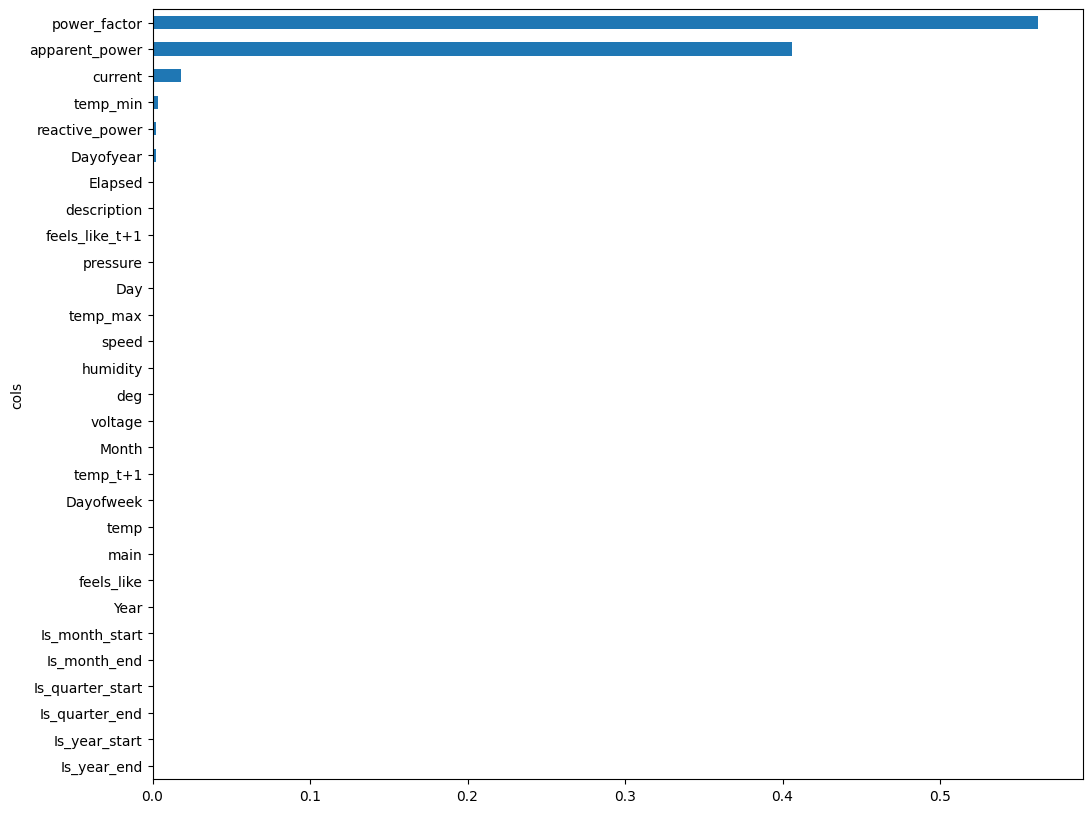

In [61]:
barh = feat_importance[:30].plot('cols', 'imp', 'barh', figsize = (12,10), legend = False)
barh = barh.invert_yaxis()
barh

We can see that for that specific tree a lot of features seem to be irrelevant to our model.

Feature importance of the whole random forest

In [62]:
feat_importance_model = rf_feat_importance(model, X_small)
feat_importance_model[:20] # cumulative effect for each of the tree

,cols,imp
3,apparent_power,0.687007
0,current,0.279843
4,power_factor,0.024142
2,reactive_power,0.003275
21,Dayofyear,0.000650
11,speed,0.000506
9,pressure,0.000480
12,deg,0.000459
28,Elapsed,0.000432
1,voltage,0.000423


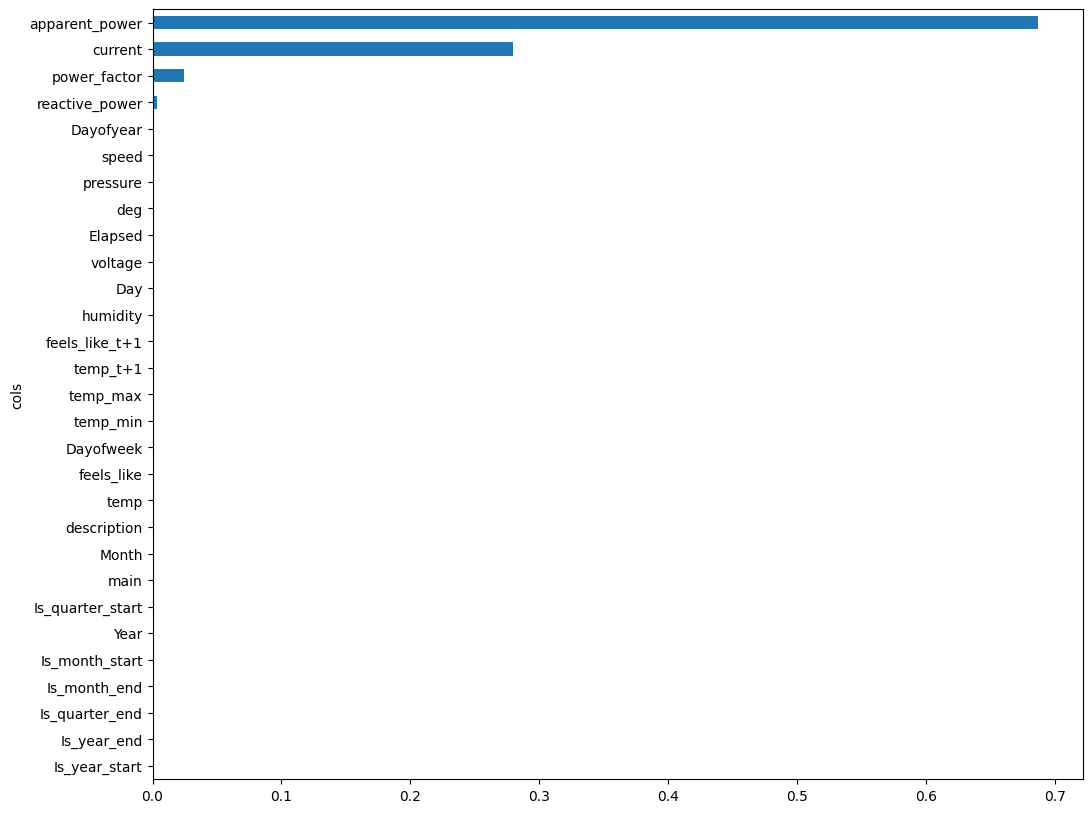

In [63]:
barh = feat_importance_model[:30].plot('cols', 'imp', 'barh', figsize = (12,10), legend = False)
barh = barh.invert_yaxis()
barh

The most important features are apparent_power (total power circulating in the circuit), power_factor( ratio of active power to apparent power) and current (flow of electric charge through the main household circuit).

In [64]:
X_small.apparent_power.value_counts()

apparent_power
303.861532    1
432.414444    1
559.387028    1
439.465014    1
495.625955    1
             ..
281.153       1
213.593861    1
281.3725      1
260.518278    1
301.580084    1
Name: count, Length: 1360, dtype: Int64

In [65]:
X_small.power_factor.value_counts()

power_factor
0.835184    1
0.930437    1
0.948574    1
0.972213    1
0.972121    1
           ..
0.803579    1
0.884413    1
0.842152    1
0.827464    1
0.818675    1
Name: count, Length: 1360, dtype: Int64

In [66]:
X_small.current.value_counts()

current
2.377639    2
2.958217    2
1.672139    2
2.492511    1
4.821309    1
           ..
2.218278    1
2.887194    1
2.274194    1
1.708       1
2.330279    1
Name: count, Length: 1357, dtype: Int64